## EDA on Pima Indians Diabetes Dataset

### Attribute Information
1. *Pregnancies*: Number of times pregnant
2. *Glucose*: Plasma glucose concentration 2 hours into an oral glucose tolerance test
3. *BloodPressure*: Diastolic blood pressure (mm Hg)
4. *SkinThickness*: Triceps skin fold thickness (mm)
5. *Insulin*: 2-hour serum insulin ($\mu$U/ml)
6. *BMI*: Body Mass Index (weight in kg/(height in m)^2)
7. *Age*: Age in years
8. *DiabetesPedigreeFunction*: It provides information about the diabetes history in relatives and the genetic relationship of those relatives to the patient.
9. *Outcome*: Target variable (0 = non-diabetic, 1 = diabetic)

### 1. Load libraries and read data

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [23]:
# Setting the default value for plots
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=15)
plt.rc('xtick', labelsize=13)
plt.rc('ytick', labelsize=13)
plt.rc('figure', titlesize=35)
plt.rc('legend', fontsize=12)

In [24]:
df=pd.read_csv('diabetes.csv')

In [25]:
print("Shape:", df.shape)
print('Duplicate rows:', df.duplicated().sum())

Shape: (768, 9)
Duplicate rows: 0


In [26]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [28]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [29]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

**Observation:** The summary statistics show a minimum value of **0** in the columns *Glucose*, *BloodPressure*, *SkinThickness*, *Insulin* and *BMI*. A living person cannot have zero blood pressure, zero glucose or a BMI of 0.
Although `df.isnull()` reports no missing values, this is misleading, because the missing data is hidden as zeros.
We therefore treat the zeros in the five columns as missing values and replace them with `NaN` in the next step.

In [30]:
cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
(df[cols_with_zero] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [31]:
cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)

In [32]:
df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

### Target variable

Status
Healthy     500
Diabetic    268
Name: count, dtype: int64 

Status
Healthy     65.1
Diabetic    34.9
Name: count, dtype: float64


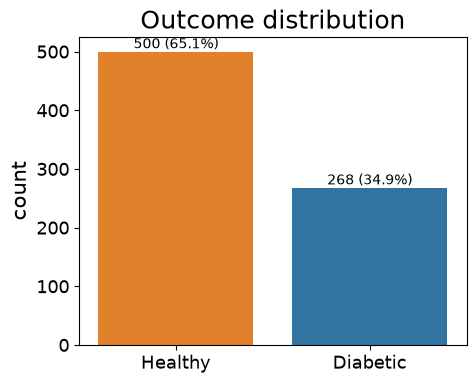

In [33]:
df['Status'] = df['Outcome'].map({0: 'Healthy', 1: 'Diabetic'})
counts = df['Status'].value_counts()
print(counts, '\n')
print((counts / len(df) * 100).round(1))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='Status', order=['Healthy', 'Diabetic'], hue='Status', legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} ({p.get_height()/len(df):.1%})',
                (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
ax.set_title('Outcome distribution'); ax.set_xlabel('')
plt.show()

65.1% healthy vs 34.9% diabetic: moderately imbalanced. A model that always predicts "healthy" would already score 65.1% accuracy, so accuracy alone is a weak yardstick here. Recall (how many diabetics we catch), ROC-AUC and PR-AUC matter more.

### Missing values

,missing,percent
Insulin,374,48.7
SkinThickness,227,29.6
BloodPressure,35,4.6
BMI,11,1.4
Glucose,5,0.7


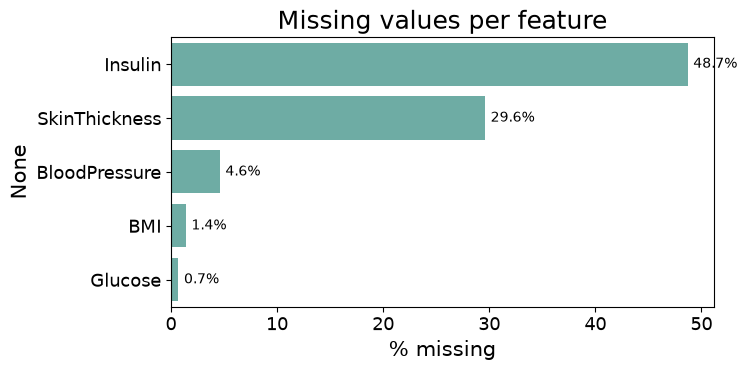

In [34]:
zero_not_valid = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Deterministic cleaning rule (0 -> NaN). It learns nothing from the data, so it is safe to apply before splitting.
df[zero_not_valid] = df[zero_not_valid].replace(0, np.nan)

missing = pd.DataFrame({'missing': df[zero_not_valid].isna().sum(),
                        'percent': (df[zero_not_valid].isna().mean() * 100).round(1)}).sort_values('missing', ascending=False)
display(missing)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=missing['percent'], y=missing.index, color='#64B6AC', ax=ax)
ax.set_xlabel('% missing'); ax.set_title('Missing values per feature')
for p in ax.patches:
    ax.annotate(f'{p.get_width():.1f}%', (p.get_width(), p.get_y() + p.get_height()/2), va='center', xytext=(4, 0), textcoords='offset points')
plt.show()

Insulin (about 49% missing) and SkinThickness (about 30%) are heavily affected.

In [35]:
df = df.drop(columns= ['Status'])

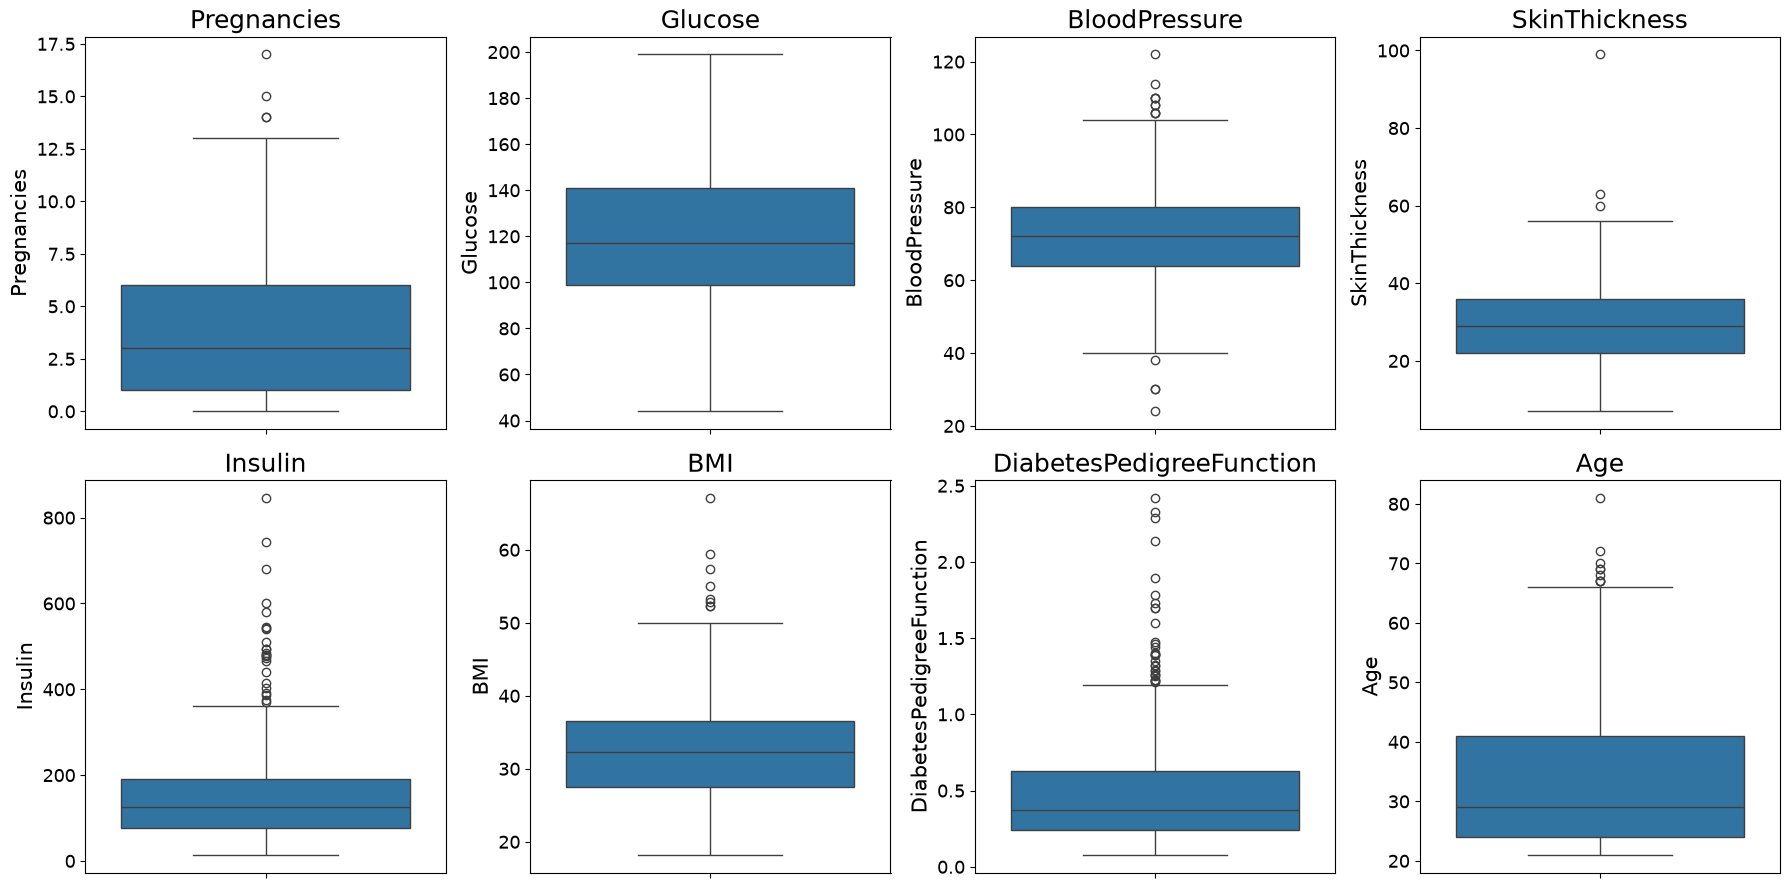

In [36]:
features = [
    'Pregnancies', 'Glucose', 'BloodPressure',
    'SkinThickness', 'Insulin', 'BMI',
    'DiabetesPedigreeFunction', 'Age'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, feature in zip(axes.flatten(), features):
    sns.boxplot(data=df, y=feature, ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

From above, we can see that there are outliers in the data and they might be valid values. So we cannot replace the missing values with the mean. Instead, we will use the median (grouped by 'Outcome') to get a much more realistic data.

### Replacing missing values

We will divide the data into two parts with diabetic and healthy females.

In [37]:
# Define a function to group data by target class (Outcome: 0 and 1) and calculate the column median
def take_median(feature):
    temp = df.groupby(['Outcome'])[[feature]].median().reset_index()
    return temp

In [38]:
# Split the dataset into diabetic (Outcome != 0) and healthy (Outcome == 0) subsets
df_dang=df[df['Outcome']!=0]
df_safe=df[df['Outcome']==0]

In [39]:
# Plot overlapping distribution curves comparing diabetic vs. healthy
def dist_plot(feature,bins):
    plt.figure(figsize=(15,6))
    sns.set_palette('Set1')
    ax=sns.distplot(df_dang[feature].dropna(),hist=True,kde=True,bins=bins,label='Diabetic')
    ax=sns.distplot(df_safe[feature].dropna(),hist=True,kde=True,bins=bins,label='Healthy')
    ax.set_xlabel(None)
    ax.legend()
    plt.title(feature,pad=20)
    plt.show()

### Glucose

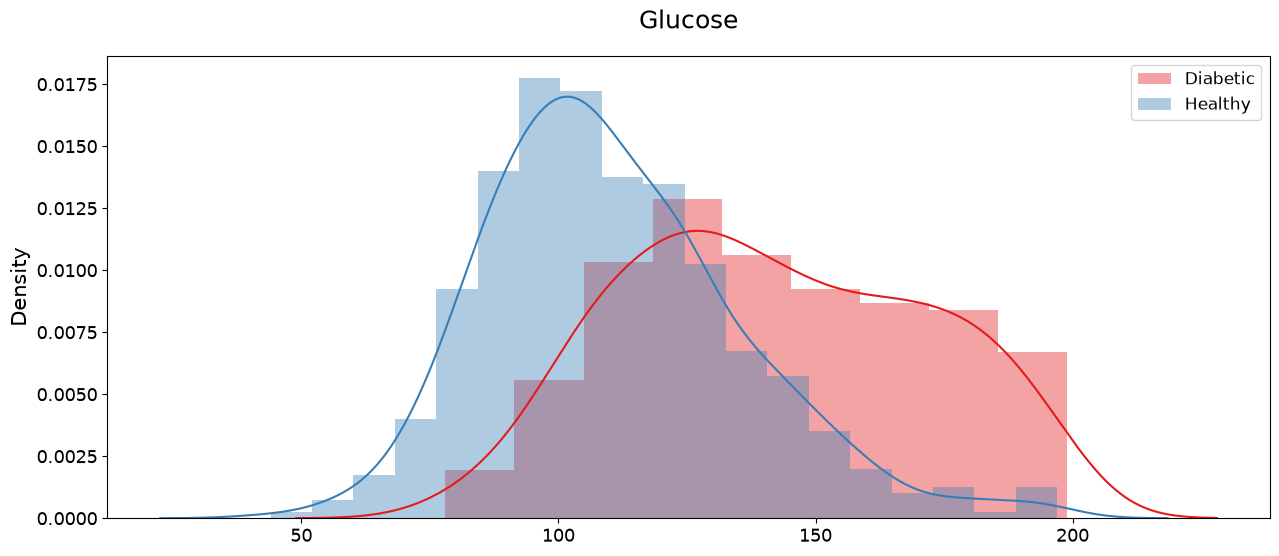

In [40]:
dist_plot('Glucose',None)

In [41]:
take_median('Glucose')

,Outcome,Glucose
0,0,107.0
1,1,140.0


In [42]:
# Replacing the NaN values with obtained median values
df.loc[(df['Outcome'] == 0 ) & (df['Glucose'].isnull()),'Glucose'] = 107
df.loc[(df['Outcome'] != 0 ) & (df['Glucose'].isnull()),'Glucose'] = 140

### BloodPressure

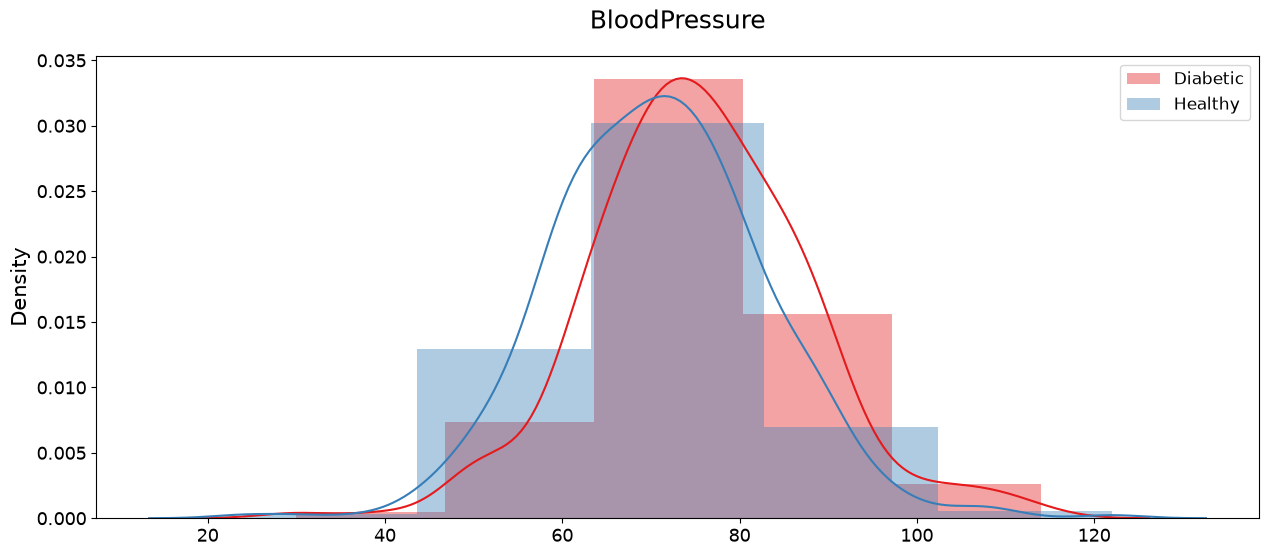

In [43]:
dist_plot('BloodPressure',5)

In [44]:
take_median('BloodPressure')

,Outcome,BloodPressure
0,0,70.0
1,1,74.5


In [45]:
df.loc[(df['Outcome'] == 0 ) & (df['BloodPressure'].isnull()),'BloodPressure'] = 70
df.loc[(df['Outcome'] != 0 ) & (df['BloodPressure'].isnull()),'BloodPressure'] = 74.5

### SkinThickness

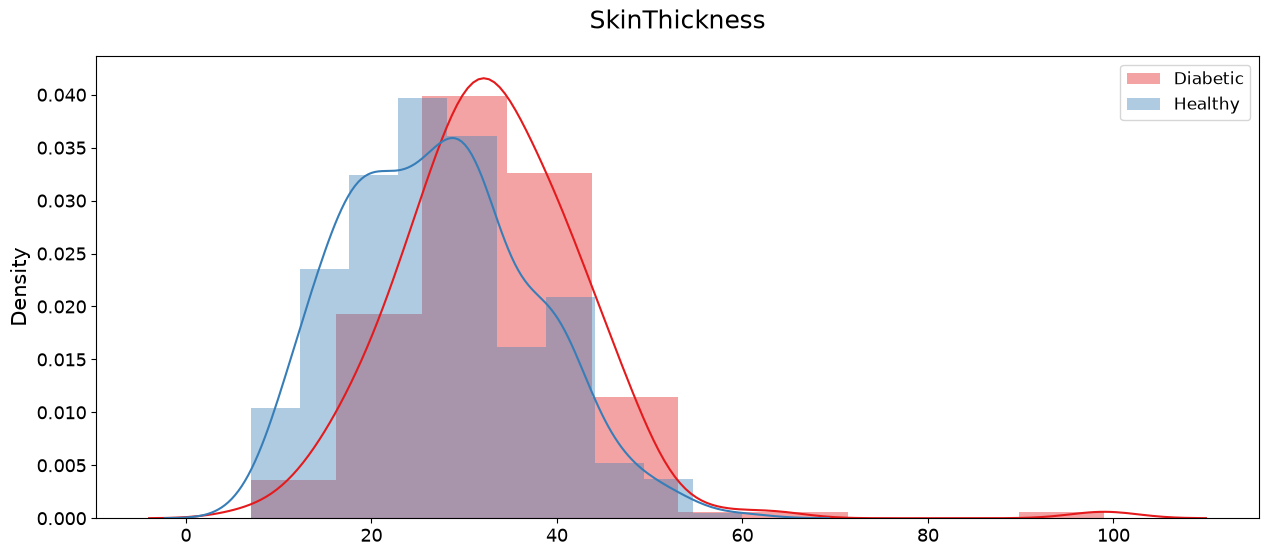

In [46]:
dist_plot('SkinThickness',10)

In [47]:
take_median('SkinThickness')

,Outcome,SkinThickness
0,0,27.0
1,1,32.0


In [48]:
df.loc[(df['Outcome'] == 0 ) & (df['SkinThickness'].isnull()),'SkinThickness'] = 27
df.loc[(df['Outcome'] != 0 ) & (df['SkinThickness'].isnull()),'SkinThickness'] = 32

### Insulin

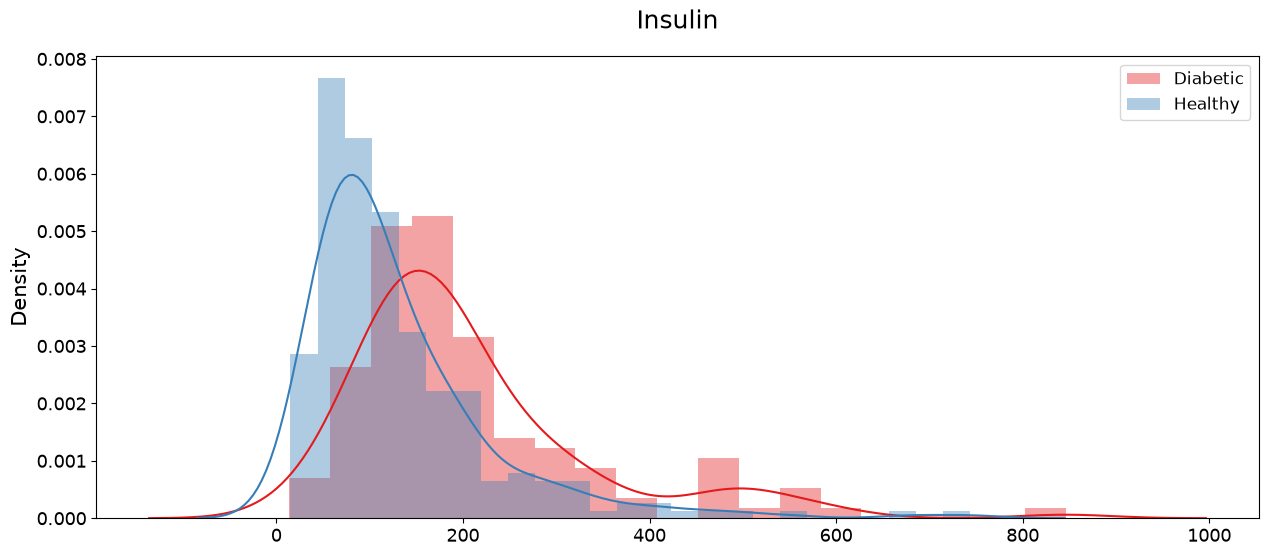

In [49]:
dist_plot('Insulin',None)

In [50]:
take_median('Insulin')

,Outcome,Insulin
0,0,102.5
1,1,169.5


In [51]:
df.loc[(df['Outcome'] == 0 ) & (df['Insulin'].isnull()),'Insulin'] = 102.5
df.loc[(df['Outcome'] != 0 ) & (df['Insulin'].isnull()),'Insulin'] = 169.5

### BMI

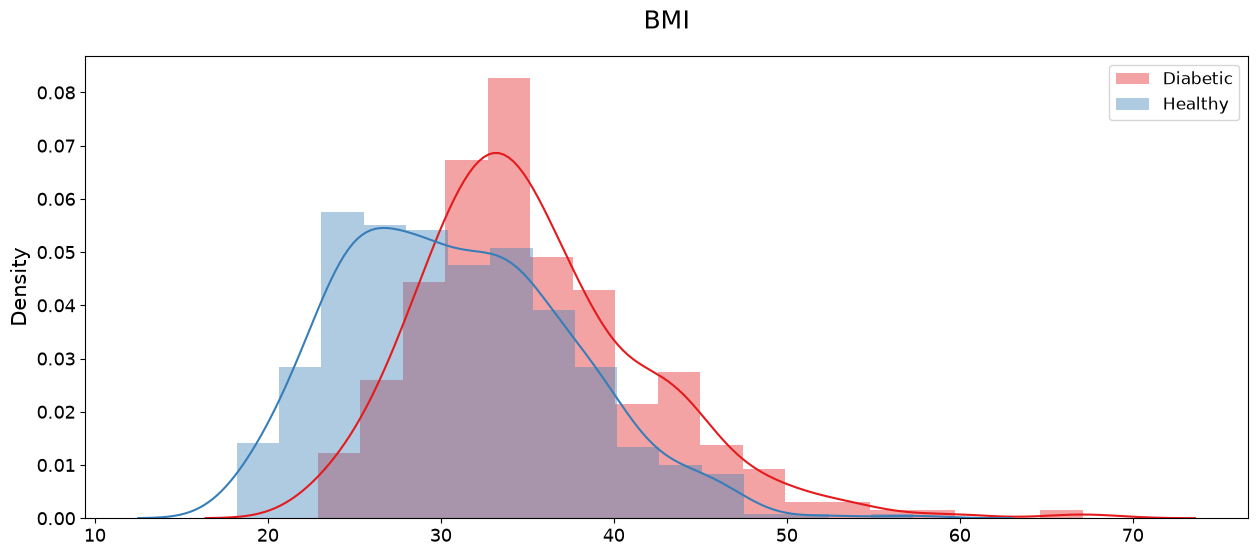

In [52]:
dist_plot('BMI',None)

In [53]:
take_median('BMI')

,Outcome,BMI
0,0,30.1
1,1,34.3


In [54]:
df.loc[(df['Outcome'] == 0 ) & (df['BMI'].isnull()),'BMI'] = 30.1
df.loc[(df['Outcome'] != 0 ) & (df['BMI'].isnull()),'BMI'] = 34.3

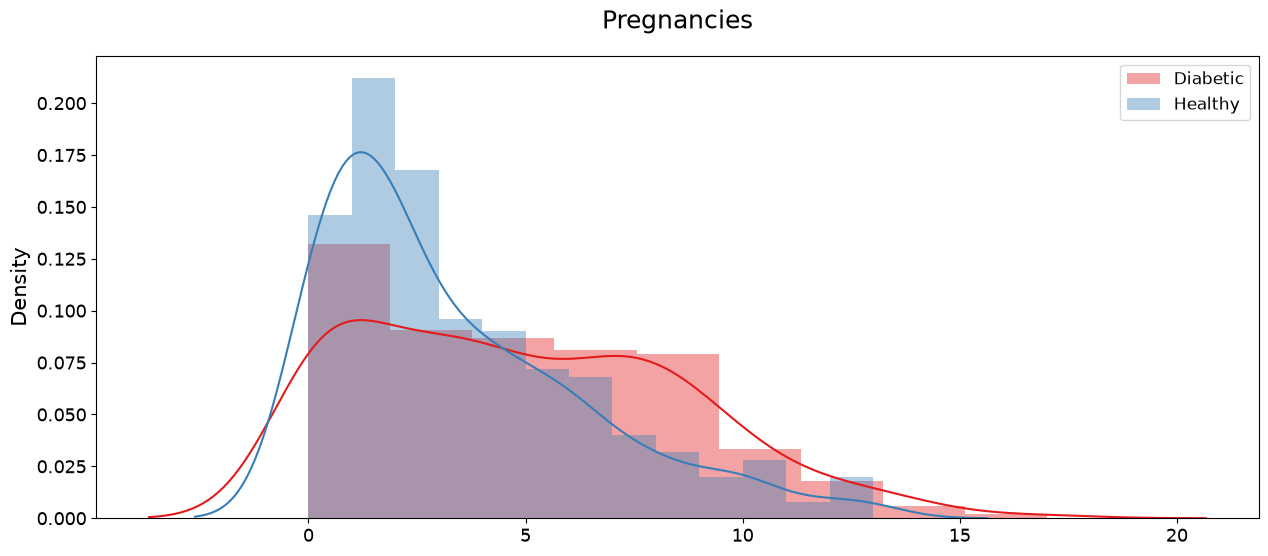

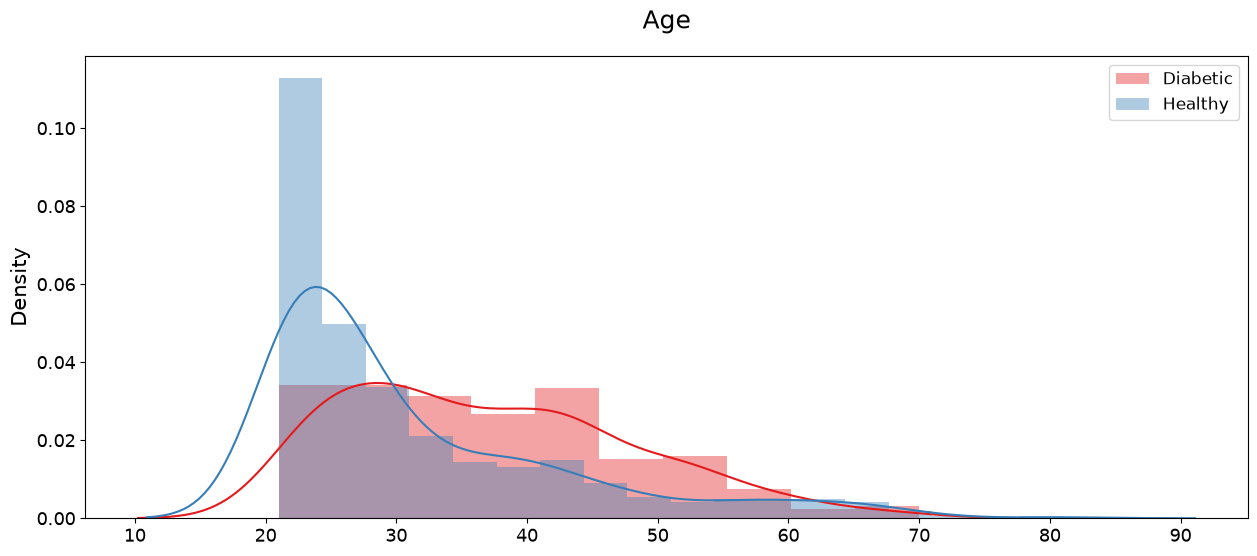

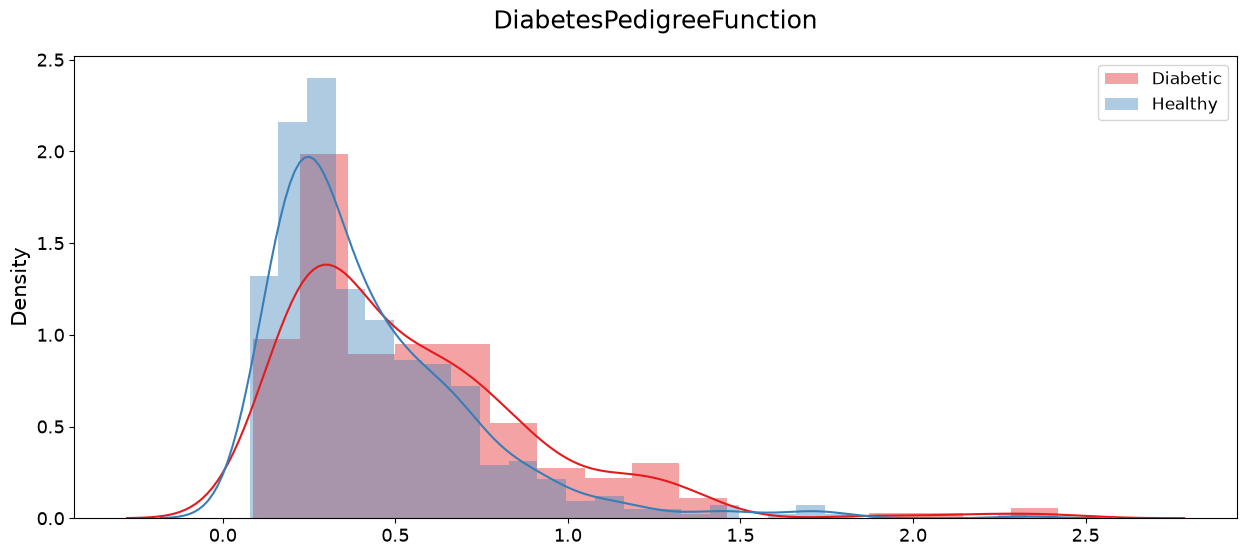

In [55]:
dist_plot('Pregnancies',None)
dist_plot('Age',None)
dist_plot('DiabetesPedigreeFunction',None)

In [56]:
# Now look again at the new data
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


### Feature Analysis

In [57]:
def feature_analysis(x_feat,y_feat):
    sns.set_style('darkgrid')
    sns.set_palette('Set1')
    x=sns.relplot(x=x_feat,y=y_feat,hue='Outcome',style='Outcome',data=df,kind='scatter',height=5,aspect=2.5)
    plt.title(x_feat+' vs '+y_feat,pad=20)
    plt.show()

First let's visualize a correlation matrix. A correlation matrix is a table showing correlation coefficients between sets of variables. Each random variable in the table is correlated with each of the other values in the table. This allows you to see which pairs have the highest correlation.

Text(0.5, 1.0, 'Features Correlation')

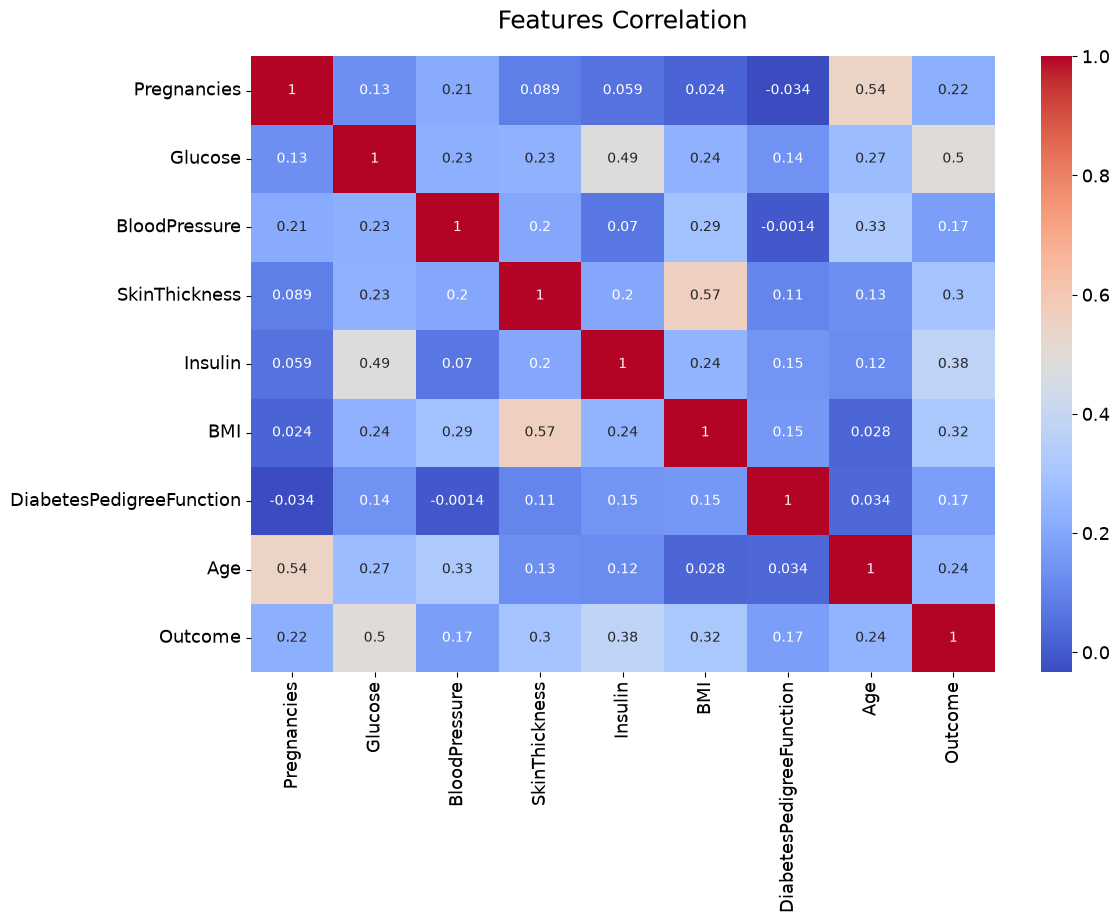

In [58]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot = True,cmap='coolwarm')
plt.title('Features Correlation',pad=20)

From the above correlation graph we can see that highly correlated features are *Pregnancies vs Age*, *Glucose vs Insulin* and *SkinThickness vs BMI*. We will first visualize these features and then explore other features as well.

### *Pregnancies vs Age*

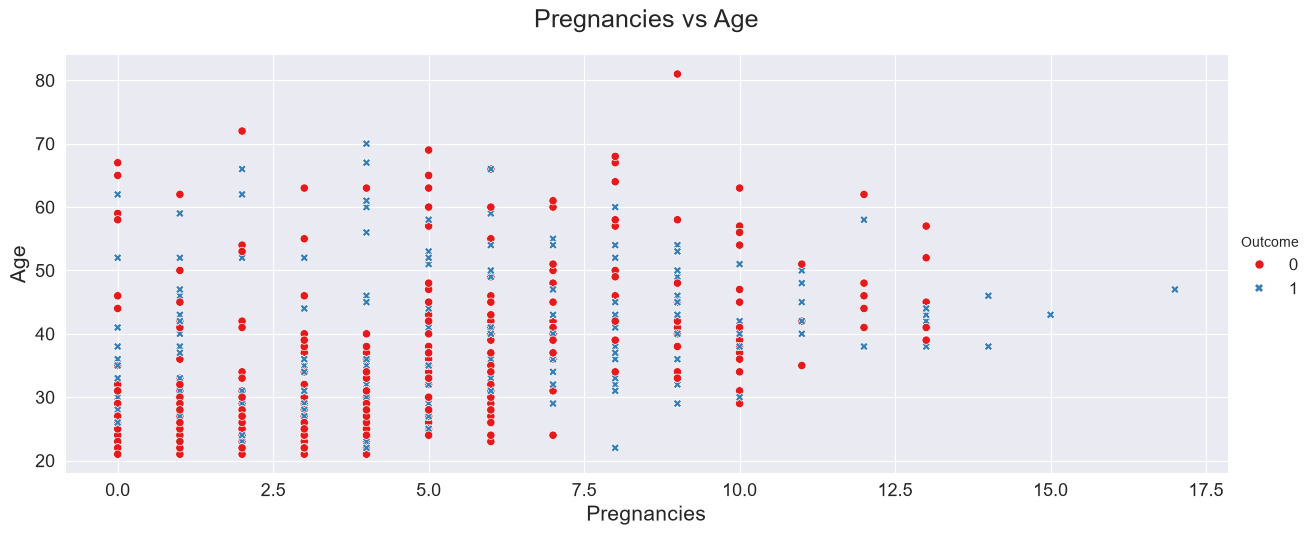

In [59]:
feature_analysis('Pregnancies','Age')

Here, healthy females are concentrated with Age <= 30 and Pregnancies <= 6

### *Glucose vs Insulin*

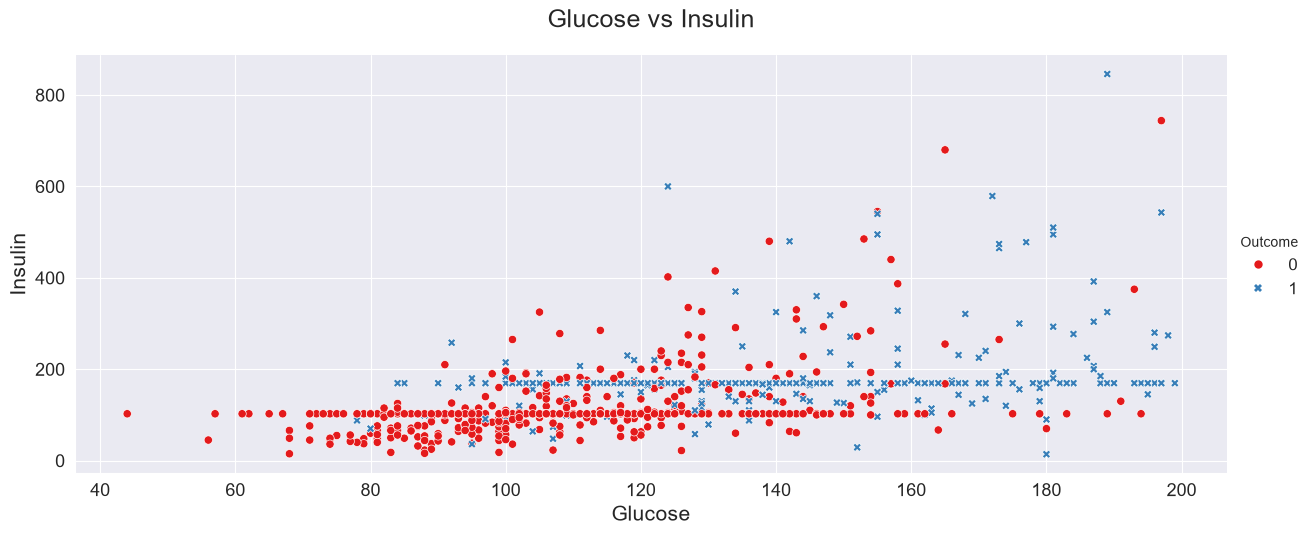

In [60]:
feature_analysis('Glucose','Insulin')

Healthy females are concentrated with Insulin < 200 and Glucose <=120

### *SkinThickness vs BMI*

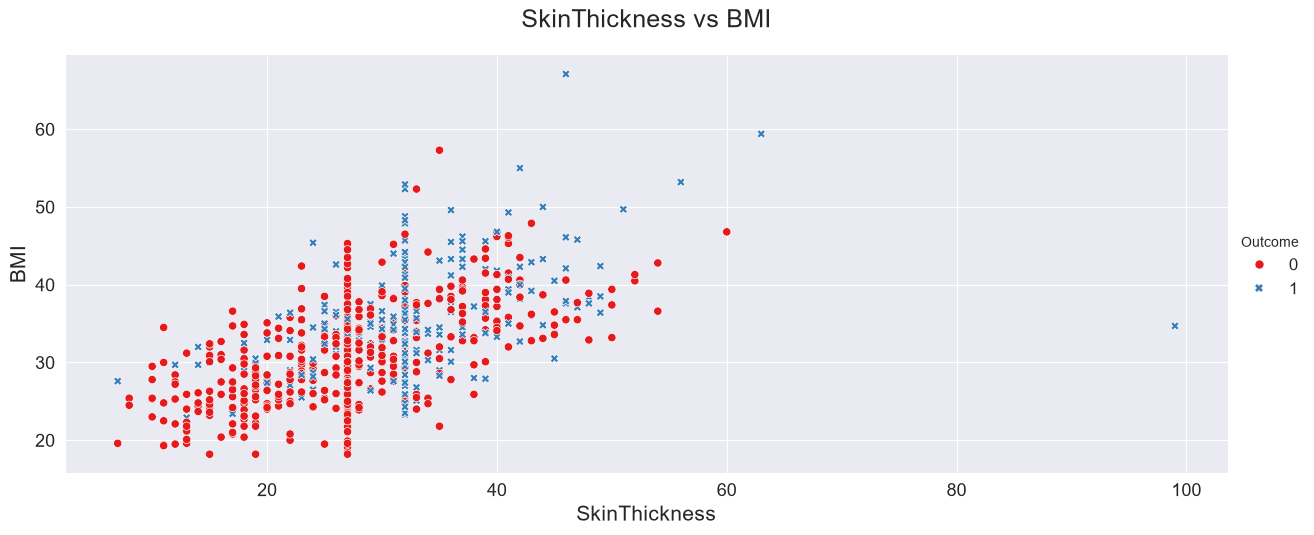

In [61]:
feature_analysis('SkinThickness','BMI')

Healthy females are concentrated with BMI <= 30 and SkinThickness <= 20

### *Glucose vs Age*

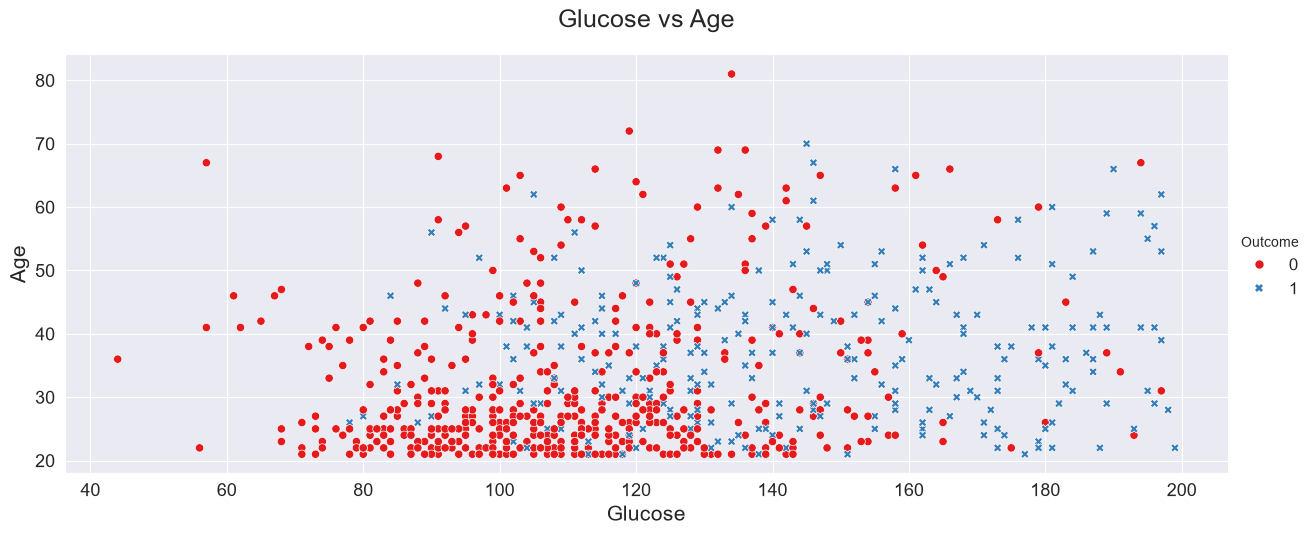

In [62]:
feature_analysis('Glucose','Age')

Healthy females are concentrated with Age <= 30 and Glucose <= 120

### *Glucose vs BloodPressure*

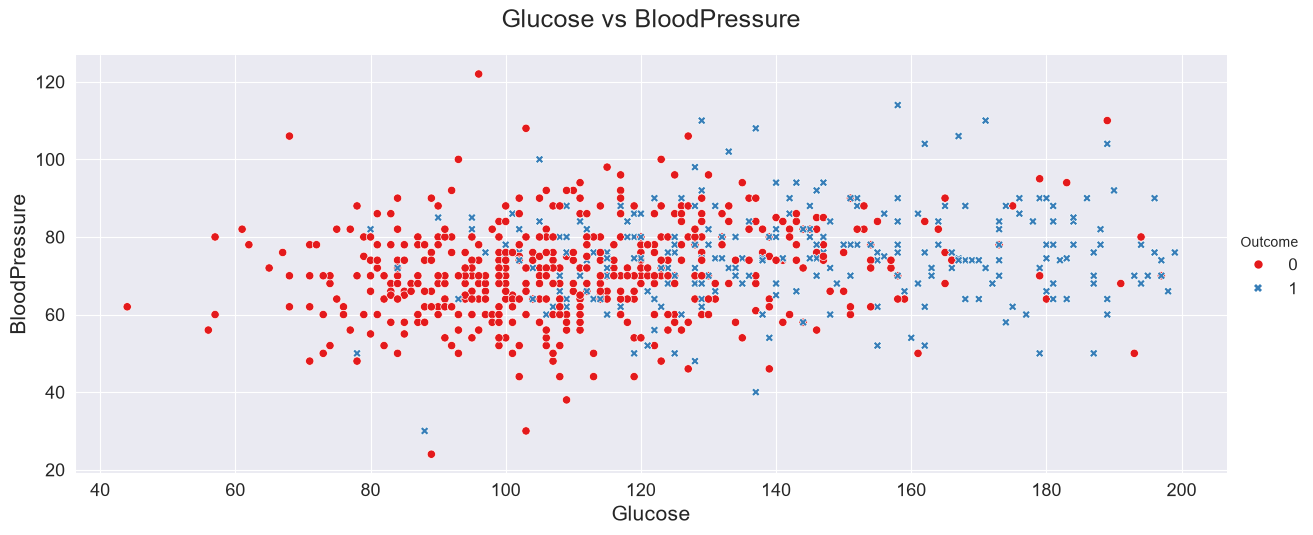

In [63]:
feature_analysis('Glucose','BloodPressure')

Healthy females are concentrated with BloodPressure <= 80 and Glucose <= 120

### *Glucose vs BMI*

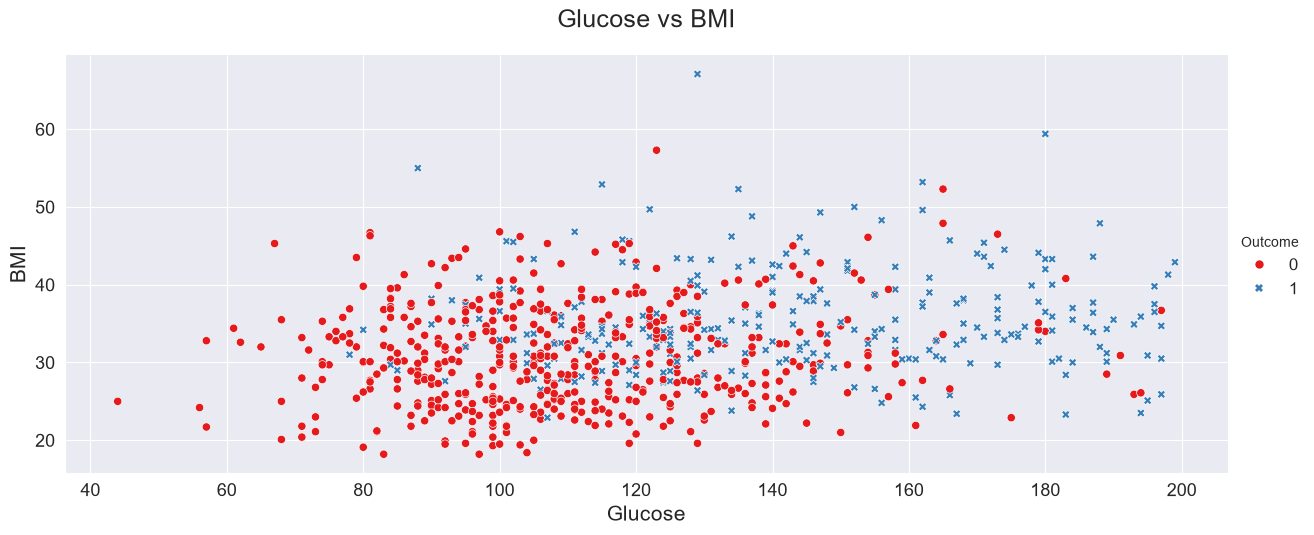

In [64]:
feature_analysis('Glucose','BMI')

Healthy females are concentrated with BMI <= 30 and Glucose <= 120

All the insight that we gathered by analyzing the different features will be very usefull for our model.